# 03 — Neural ODEs: black-box and sparse-library models

* **N1 (black box).** $f_\theta(x)= s\odot g_\theta\big((x-\mu)/s\big)/t_{\rm char}$ with $g_\theta$ a $\tanh$ MLP ($2\times 64$). Trained with Adam on minibatches of shooting windows, with a window-length curriculum $H\in\{0.1,0.25,0.5,1\}\,t_{\rm char}$. Equations are obtained afterwards by *symbolic distillation*, i.e. STLSQ of $f_\theta(S_i)$ on $\Theta(S_i)$ over the denoised shooting states.
* **N2 (sparse library).** $f_\Xi(x)=s\odot\Theta(x/s)\,\Xi/t_{\rm char}$, fitted by differentiating through the RK4 integrator:
  1. Levenberg–Marquardt on the one-step flow map,
  2. full-batch L-BFGS over $(\Xi, S)$ with geometric continuation in the window length $K=1,2,3,5,8,\dots$,
  3. multistart over $\{0,\ \Xi_{\rm OLS}\}$ (and $\Xi_{\rm WSINDy}$ for the warm-started variant **N2-WS**),
  4. sequential thresholding with trajectory-matching refits along a regularisation path, selected on the held-out blocks.

The neural models run on a cross-shaped sub-grid of the classical design: a sampling sweep at $\varepsilon=1\%$ and a noise sweep at $\Delta t_{\rm obs}=t_{\rm char}/15$, 3 seeds each. Trained models are cached in `results/models/`; a fresh run of this notebook on 2 CPU cores takes roughly three hours. `RUN_ON_COLAB.ipynb` extends the grid on a GPU.

In [1]:
import sys, os, time, pickle
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from src import experiment as E, plotting as P
from src.sweeps import neural_job, run_parallel, save_rows
from src.library import PolyLibrary
P.setup()
MET = "../results/metrics"
SEEDS = [0, 1, 2]
METHODS = ["N2-Lib", "N2-Lib-WS", "N1-MLP"]
CONFIGS = [(r, 0.01) for r in E.DT_RATIOS] + [(1/15, e) for e in [0.0, 0.02, 0.05, 0.10, 0.20]]

In [2]:
jobs = [(name, r, eps, seed, m, {}) for m in METHODS for seed in SEEDS
        for name in ["lorenz", "lv4"] for (r, eps) in CONFIGS]
print(len(jobs), "trainings")
t0 = time.time()
rows = run_parallel(neural_job, jobs, workers=2, log_every=10)
print(f"elapsed {(time.time() - t0) / 60:.1f} min")
df, coefs = save_rows(rows, f"{MET}/neural_grid.csv", f"{MET}/neural_coefs.pkl")
print("failed:", int(df["error"].notna().sum()) if "error" in df else 0)

162 trainings


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


10/162 jobs done


20/162 jobs done


30/162 jobs done


... (11 outputs left out)

150/162 jobs done


160/162 jobs done


162/162 jobs done


elapsed 209.4 min
failed: 0


In [3]:
cols = ["coef_err", "f1", "n_terms", "vpt_id", "vpt_ood", "w1", "lyap_est", "fit_time"]
df.groupby(["system", "method", "dt_ratio", "noise"])[cols].median().round(3)

coef_err     f1  n_terms  vpt_id  vpt_ood  \
system method    dt_ratio noise                                              
lorenz N1-MLP    0.013333 0.01      0.211  0.667     14.0   1.752    0.016   
                 0.066667 0.00      0.238  0.824     10.0   1.455    0.015   
                          0.01      0.262  0.824     10.0   1.174    0.015   
                          0.02      0.251  0.824     10.0   1.357    0.015   
                          0.05      0.402  0.560     18.0   1.370    0.015   
                          0.10      0.569  0.519     20.0   1.379    0.016   
                          0.20      0.576  0.609     16.0   1.258    0.016   
                 0.133333 0.01      0.387  0.560     18.0   1.400    0.015   
                 0.266667 0.01      1.153  0.452     24.0   1.080    0.015   
       N2-Lib    0.013333 0.01      0.003  1.000      7.0   5.598    7.090   
                 0.066667 0.00      0.000  1.000      7.0   9.136    9.730   
                          0.01      0.009  1.000      7.0   4.110    4.299   
                          0.02      0.021  0.700     13.0   3.560    3.857   
                          0.05      0.090  0.700     13.0   2.471    1.858   
                          0.10      0.213  0.560     18.0   1.884    0.545   
                          0.20      0.950  0.636     15.0   1.330    0.296   
                 0.133333 0.01      0.031  0.824     10.0   4.005    4.635   
                 0.266667 0.01      0.052  0.636     15.0   3.512    3.259   
       N2-Lib-WS 0.013333 0.01      0.003  1.000      7.0   5.598    7.090   
                 0.066667 0.00      0.000  1.000      7.0   9.136    9.730   
                          0.01      0.009  1.000      7.0   4.110    4.301   
                          0.02      0.021  0.700     13.0   3.560    3.857   
                          0.05      0.089  0.700     13.0   2.486    1.866   
                          0.10      0.215  0.560     18.0   2.033    0.994   
                          0.20      0.938  0.636     15.0   1.467    0.297   
                 0.133333 0.01      0.031  0.824     10.0   3.648    4.561   
                 0.266667 0.01      0.052  0.636     15.0   3.402    3.259   
lv4    N1-MLP    0.013333 0.01      2.679  0.394     54.0   1.107    0.011   
                 0.066667 0.00      4.456  0.432     57.0   0.806    0.011   
                          0.01      4.978  0.453     58.0   0.875    0.011   
                          0.02      4.932  0.421     56.0   0.869    0.011   
                          0.05      4.365  0.442     53.0   0.860    0.011   
                          0.10      2.274  0.444     49.0   0.757    0.011   
                          0.20      1.541  0.452     51.0   0.673    0.012   
                 0.133333 0.01      3.443  0.442     58.0   0.445    0.012   
                 0.266667 0.01      6.560  0.447     58.0   0.381    0.011   
       N2-Lib    0.013333 0.01      1.515  0.442     60.0   3.047    0.216   
                 0.066667 0.00      0.001  1.000     17.0   5.687    5.463   
                          0.01      0.692  0.447     59.0   3.357    0.651   
                          0.02      2.343  0.466     56.0   1.560    0.148   
                          0.05      6.421  0.459     57.0   0.687    0.011   
                          0.10      8.700  0.442     60.0   0.958    0.009   
                          0.20      7.842  0.447     59.0   0.437    0.009   
                 0.133333 0.01      0.416  0.442     60.0   1.705    0.644   
                 0.266667 0.01      5.235  0.442     60.0   1.670    0.012   
       N2-Lib-WS 0.013333 0.01      1.515  0.442     60.0   3.046    0.216   
                 0.066667 0.00      0.001  1.000     17.0   5.687    5.463   
                          0.01      0.692  0.447     59.0   3.357    0.651   
                          0.02      2.343  0.466     56.0   1.560    0.178   
                          0.05      6.421  0.459     57

## Training dynamics and the selection path

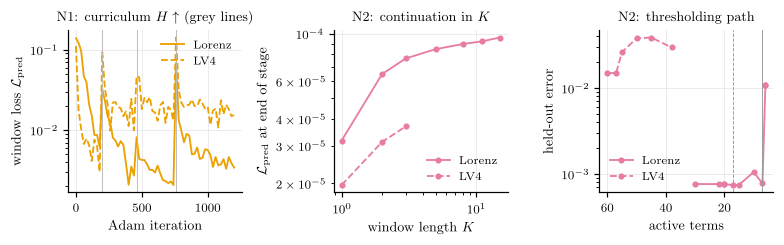

In [4]:
def load(name, method, r, eps, seed=0):
    tag = E._tag(name, method, r, eps, seed)
    return torch.load(f"../results/models/{tag}.pt", weights_only=False)

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.3))
for name, ls in [("lorenz", "-"), ("lv4", "--")]:
    ck = load(name, "N1-MLP", 1/15, 0.01)
    H = ck["train"]["history"]
    it = np.arange(len(H)) * 20
    axes[0].semilogy(it, H[:, 3], ls, color=P.COLORS["N1-MLP"], label=("Lorenz" if name == "lorenz" else "LV4"))
    for b in np.where(np.diff(H[:, 0]) != 0)[0]:
        axes[0].axvline(it[b + 1], color="#bbbbbb", lw=0.5)
axes[0].set_xlabel("Adam iteration"); axes[0].set_ylabel(r"window loss $\mathcal{L}_{\rm pred}$")
axes[0].set_title(r"N1: curriculum $H\uparrow$ (grey lines)"); axes[0].legend(frameon=False)

for name, ls in [("lorenz", "-"), ("lv4", "--")]:
    ck = load(name, "N2-Lib", 1/15, 0.01)
    H = ck["train"]["history"]
    if len(H):
        axes[1].semilogy(H[:, 0], H[:, 2], "o" + ls, ms=3, color=P.COLORS["N2-Lib"],
                         label=("Lorenz" if name == "lorenz" else "LV4"))
axes[1].set_xscale("log"); axes[1].set_xlabel(r"window length $K$"); axes[1].set_ylabel(r"$\mathcal{L}_{\rm pred}$ at end of stage")
axes[1].set_title("N2: continuation in $K$"); axes[1].legend(frameon=False)

for name, ls in [("lorenz", "-"), ("lv4", "--")]:
    info = load(name, "N2-Lib", 1/15, 0.01)["info"]
    axes[2].semilogy(info["path_nnz"], info["path_err"], "o" + ls, ms=3, color=P.COLORS["N2-Lib"],
                     label=("Lorenz" if name == "lorenz" else "LV4"))
    s = E.get_sys(name)
    axes[2].axvline(np.count_nonzero(s.Xi_true), color="#999999", lw=0.6, ls=ls)
axes[2].invert_xaxis(); axes[2].set_xlabel("active terms"); axes[2].set_ylabel("held-out error")
axes[2].set_title("N2: thresholding path"); axes[2].legend(frameon=False)
fig.tight_layout()
P.save(fig, "fig03_training")
plt.show()

## Recovered equations (seed 0)

In [5]:
for name, (r, eps) in [("lorenz", (4/15, 0.01)), ("lorenz", (1/15, 0.01)), ("lv4", (1/15, 0.0))]:
    s = E.get_sys(name); lib = PolyLibrary(s.d, 2, s.symbols)
    print(f"===== {name}, dt = {r * s.t_char:.3g}, noise = {eps:.0%}")
    for m in METHODS:
        Xi = coefs[(name, m, round(r, 5), eps, 0, False)]
        sub = df[(df.system == name) & (df.method == m) & (df.dt_ratio.round(5) == round(r, 5)) & (df.noise == eps) & (df.seed == 0)]
        print(f"[{m}] coef_err = {sub.coef_err.values[0]:.4f}")
        print(lib.pretty(Xi, s.symbols, tol=1e-12)); print()

===== lorenz, dt = 0.2, noise = 1%
[N2-Lib] coef_err = 0.0158
dx/dt = -9.587 x +9.727 y -0.021 x z +0.017 y z
dy/dt = +28.025 x -1.018 y -1.000 x z
dz/dt = -2.655 z +1.000 x y

[N2-Lib-WS] coef_err = 0.0158
dx/dt = -9.587 x +9.727 y -0.021 x z +0.017 y z
dy/dt = +28.025 x -1.018 y -1.000 x z
dz/dt = -2.655 z +1.000 x y

[N1-MLP] coef_err = 1.5768
dx/dt = -9.048 +1.148 x +3.258 y +1.448 z +0.516 x^2 -0.495 x y -0.374 x z +0.100 y^2 +0.240 y z -0.051 z^2
dy/dt = -13.995 +16.809 x +2.043 y +2.035 z +0.488 x^2 -0.642 x y -0.747 x z +0.147 y^2 +0.026 y z -0.055 z^2
dz/dt = -42.843 -4.958 x +2.001 z +0.967 x y +0.190 x z -0.108 z^2

===== lorenz, dt = 0.05, noise = 1%
[N2-Lib] coef_err = 0.0062
dx/dt = -10.078 x +10.094 y
dy/dt = +27.847 x -0.994 y -0.995 x z
dz/dt = -2.666 z +0.999 x y

[N2-Lib-WS] coef_err = 0.0061
dx/dt = -10.079 x +10.094 y
dy/dt = +27.850 x -0.994 y -0.996 x z
dz/dt = -2.666 z +0.999 x y

[N1-MLP] coef_err = 0.2623
dx/dt = -7.633 x +8.126 y -0.089 x z +0.077 y z
dy/dt =